In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from plotting import *
from HeteroBilayer import HeteroBilayer
import utils
import analytic_metric

In [4]:
plt.rcParams.update({
    'figure.figsize': (7, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': False,   # remove top/right borders
    'axes.spines.right': False,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

### Localization plots

#### 1 Band

In [47]:
sys = HeteroBilayer(theta_deg=2.0, psi_deg=26, V=6.6, n_shells=10)

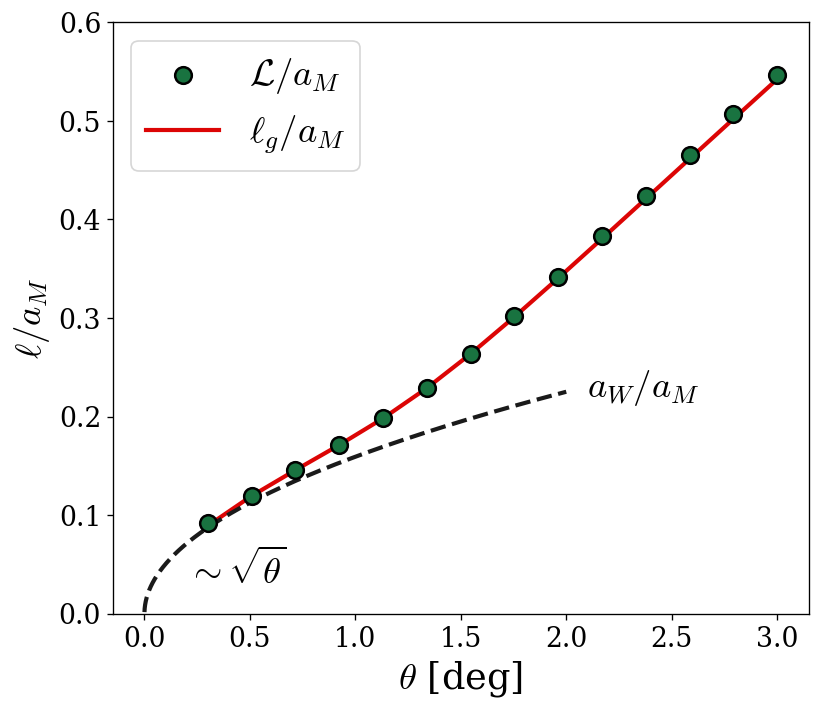

In [ ]:
thetas = np.linspace(0.3, 3.0, 14)
thetas2 = np.logspace(-4, np.log10(2.0), 1000)
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

scale_W = 6.0

NxR = 100
NyR = 100

NxK = 15
NyK = 15

localization_func = []
metric_length = []

resx = 300
resk = 15
alphax = 0.4
alphak = 0.8

fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)

for th in thetas:
    sys.theta_deg = th

    x = np.linspace(-scale_W, scale_W, resx)
    y = np.linspace(-scale_W, scale_W, resx)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell(Nx=15, Ny=15)

    fun = lambda xx, yy: xx**2 + yy**2
    wannier = sys.wannier_function(X, Y, k_points, trial_centers=[np.zeros(2)], R0=np.zeros(2))[0, :, :]
    rW = np.sqrt(sys.integrate_wannier(fun, wannier, X, Y))
    localization_func.append(rW)

    integral = sys.integrate_trace(Nx=resk, Ny=resk)
    lg = np.sqrt(integral)
    metric_length.append(lg)

ax.scatter(thetas, np.array(localization_func), facecolors='#197340', edgecolors='k', linewidth=1.5,
            s=100, marker='o', label=r"$\mathcal{L}/a_M$", zorder=3)
ax.plot(thetas, np.array(metric_length), color=np.array([220, 5, 5])/255, linestyle='-', label=r"$\ell_g/a_M$", linewidth=2.5)
ax.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, color=[.1, .1, .1], linewidth=2.5, linestyle='--')
ax.text(0.2, 0.03, r"$\sim\sqrt{\theta}$", fontsize=22)
ax.text(2.1, 0.22, r"$a_W/a_M$", fontsize=22)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=22)
ax.set_ylabel(r"$\ell / a_M$", fontsize=22)

plt.tight_layout()
plt.ylim([0.0, .6])
plt.legend(fontsize=22)

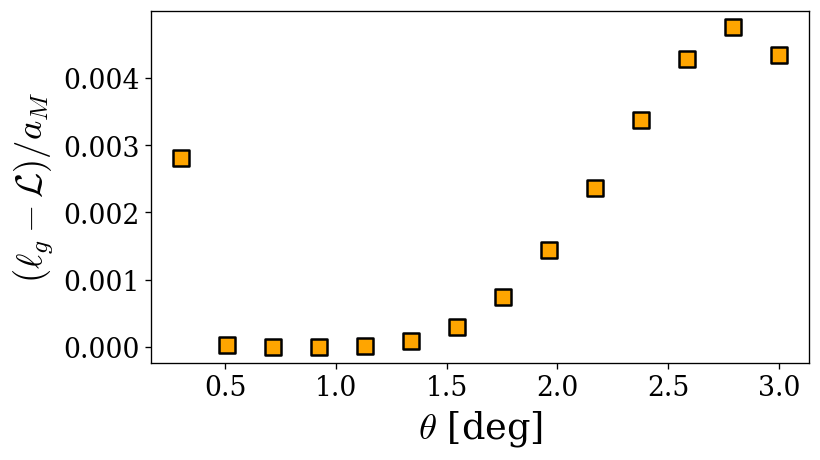

In [49]:
fig, ax = plt.subplots(1, 1, figsize=(7, 4))
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)

ax.scatter(thetas, np.array(rW_values)-np.array(l0_valuesH), facecolors='orange', edgecolors='k', linewidth=1.5,
            s=100, marker='s', zorder=3)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=22)
ax.set_ylabel(r"$(\ell_g - \mathcal{L}) / a_M$", fontsize=22)

plt.tight_layout()

#### 2 Band

In [55]:
sys = HeteroBilayer(theta_deg=2.0, psi_deg=58, V=6.6, n_shells=10)

In [60]:
thetas = np.linspace(0.3, 3.0, 14)
thetas2 = np.logspace(-4, np.log10(2.0), 1000)
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

scale_W = 8.0

NxR = 200
NyR = 200

NxK = 15
NyK = 15

localization_func = []
metric_length = []

resx = 300
resk = 15
alphax = 0.4
alphak = 0.8

for th in thetas:
    sys.theta_deg = th

    x = np.linspace(-scale_W, scale_W, resx)
    y = np.linspace(-scale_W, scale_W, resx)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell(Nx=15, Ny=15)

    ## Trial functions centers
    RA = np.zeros(2)
    RB = (2 * sys.a1 - sys.a2) / 3
    ##

    wanniers = sys.wannier_function(X, Y, k_points, trial_centers=np.array([RA, RB]), bands=(-2, -1))
    wannierA = wanniers[0, :, :]
    wannierB = wanniers[1, :, :]

    funA = lambda xx, yy: xx**2 + yy**2
    LA = sys.integrate_wannier(funA, wannierA, X, Y)

    funB = lambda xx, yy: (xx - RB[0])**2 + (yy - RB[1])**2
    LB = sys.integrate_wannier(funB, wannierB, X, Y)

    localization_func.append( np.sqrt(LA + LB) )

    integral = sys.integrate_trace(Nx=resk, Ny=resk, bands=(-2, -1))
    lg = np.sqrt(integral)
    metric_length.append(lg)

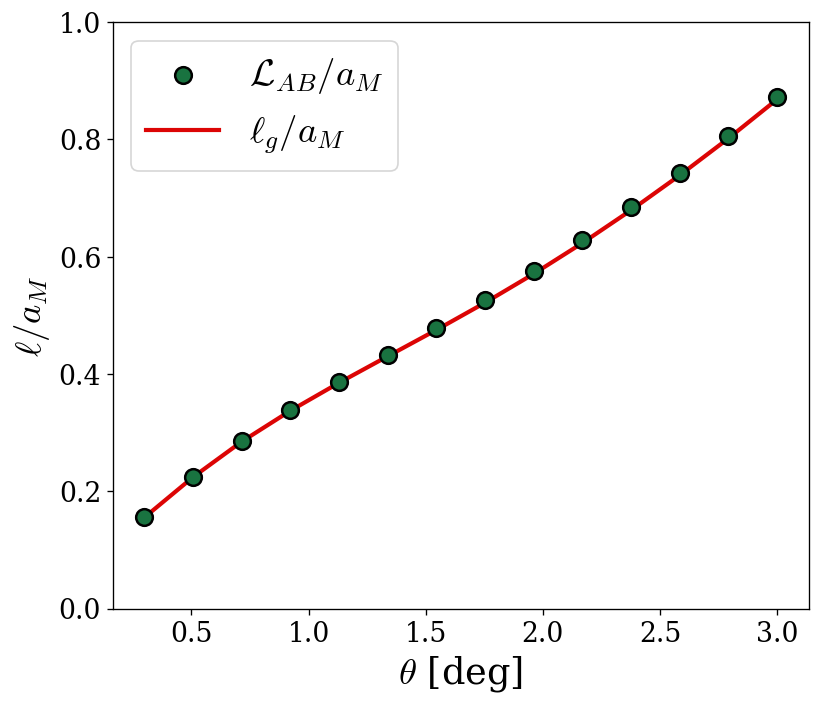

In [61]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)

ax.scatter(thetas, np.array(localization_func), facecolors='#197340', edgecolors='k', linewidth=1.5,
            s=100, marker='o', label=r"$\mathcal{L}_{AB}/a_M$", zorder=3)
ax.plot(thetas, np.array(metric_length), color=np.array([220, 5, 5])/255, linestyle='-', label=r"$\ell_g/a_M$", linewidth=2.5)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=22)
ax.set_ylabel(r"$\ell / a_M$", fontsize=22)

plt.tight_layout()
plt.ylim([0.0, 1.0])
plt.legend(fontsize=22)

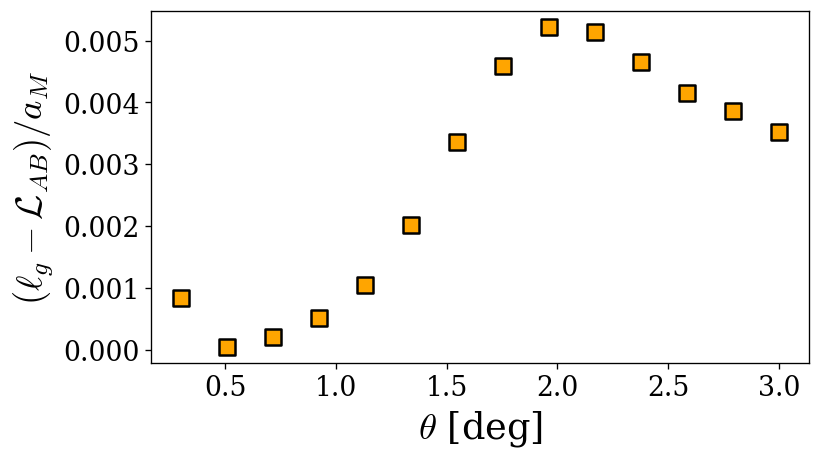

In [63]:
fig, ax = plt.subplots(1, 1, figsize=(7, 4))
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)

ax.scatter(thetas, np.array(localization_func)-np.array(metric_length), facecolors='orange', edgecolors='k', linewidth=1.5,
            s=100, marker='s', zorder=3)

ax.set_xlabel(r"$\theta$ [deg]", fontsize=22)
ax.set_ylabel(r"$(\ell_g - \mathcal{L}_{AB}) / a_M$", fontsize=22)

plt.tight_layout()